# Chương 4 bài 2 Cây quyết định và rừng cây tiểu đường

**Nguồn:** Lab phân lớp, mục 2.1.4, trang 7

**Đề bài:** Xây dựng cây quyết định và rừng cây trên dữ liệu bệnh tiểu đường.

Code triển khai bài tập theo dữ liệu đã cung cấp; không phải đoạn chép nguyên văn bài mẫu.

In [1]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data').is_dir() and (p / 'README.md').is_file())
DATA = ROOT / 'data'
OUT = ROOT / 'ket_qua' / 'C4_BT02_Cay_Rung_TieuDuong'
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'figure.figsize': (8, 4)})

def save_fig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140, bbox_inches='tight')
    plt.show()

def save_summary(values):
    (OUT / 'tom_tat.json').write_text(
        json.dumps(values, ensure_ascii=False, indent=2), encoding='utf-8'
    )


## 1 Đọc Pima và đánh dấu số 0 không hợp lệ

In [2]:
columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
           'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
raw = pd.read_csv(DATA / 'pima-indians-diabetes.csv', header=None, names=columns)
invalid_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
zero_counts = raw[invalid_zero].eq(0).sum()
df = raw.copy()
df[invalid_zero] = df[invalid_zero].replace(0, np.nan)
print('Raw shape:', raw.shape)
print('Zero placeholders:\n', zero_counts)
print('Class distribution:\n', df['Outcome'].value_counts())

X = df.drop(columns='Outcome')
y = df['Outcome']

Raw shape: (768, 9)
Zero placeholders:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
Class distribution:
 Outcome
0    500
1    268
Name: count, dtype: int64


## 2 Chia dữ liệu

In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Test classes:', y_test.value_counts().to_dict())

Train: (614, 8) Test: (154, 8)
Test classes: {0: 100, 1: 54}


## 3 Điền trung vị từ train

In [4]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')
X_train_ready = imputer.fit_transform(X_train)
X_test_ready = imputer.transform(X_test)
feature_names = list(X.columns)

## 4 Tạo mô hình

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
models = {
    'DecisionTree': DecisionTreeClassifier(max_depth=4, random_state=42),
    'RandomForest': RandomForestClassifier(n_estimators=100, max_depth=8,
                                            random_state=42, n_jobs=2)
}

## 5 Huấn luyện và đánh giá

DecisionTree 
               precision    recall  f1-score   support

           0       0.83      0.84      0.84       100
           1       0.70      0.69      0.69        54

    accuracy                           0.79       154
   macro avg       0.76      0.76      0.76       154
weighted avg       0.78      0.79      0.79       154

RandomForest 
               precision    recall  f1-score   support

           0       0.77      0.86      0.81       100
           1       0.67      0.52      0.58        54

    accuracy                           0.74       154
   macro avg       0.72      0.69      0.70       154
weighted avg       0.73      0.74      0.73       154

       model  accuracy  precision  recall     f1  roc_auc  recall_negative  balanced_accuracy  average_precision
DecisionTree    0.7857     0.6981  0.6852 0.6916   0.7887             0.84             0.7626             0.6203
RandomForest    0.7403     0.6667  0.5185 0.5833   0.8067             0.86             0.6

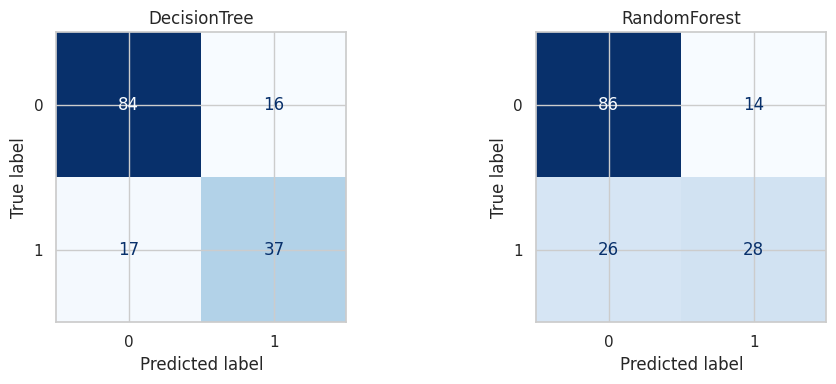

In [6]:
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             classification_report, ConfusionMatrixDisplay)
rows = []
for name, model in models.items():
    model.fit(X_train_ready, y_train)
    pred = model.predict(X_test_ready)
    prob = model.predict_proba(X_test_ready)[:, list(model.classes_).index(1)]
    rows.append({'model':name, 'accuracy':float(accuracy_score(y_test,pred)),
                 'precision':float(precision_score(y_test,pred,zero_division=0)),
                 'recall':float(recall_score(y_test,pred,zero_division=0)),
                 'f1':float(f1_score(y_test,pred,zero_division=0)),
                 'roc_auc':float(roc_auc_score(y_test,prob)),
                 'recall_negative':float(recall_score(y_test,pred,pos_label=0,zero_division=0)),
                 'balanced_accuracy':float(balanced_accuracy_score(y_test,pred)),
                 'average_precision':float(average_precision_score(y_test,prob))})
    print(name, '\n', classification_report(y_test,pred,zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model,X_test_ready,y_test,ax=ax,
                                         cmap='Blues',colorbar=False)
    ax.set_title(name)
save_fig('01_confusion_matrices.png')
results = pd.DataFrame(rows)
print(results.round(4).to_string(index=False))
results.to_csv(OUT / 'metrics.csv',index=False)
save_summary({'train_rows':len(y_train),'test_rows':len(y_test),
              'positive_label':1,'metrics':rows})

## 6 Vẽ cây và độ quan trọng đặc trưng

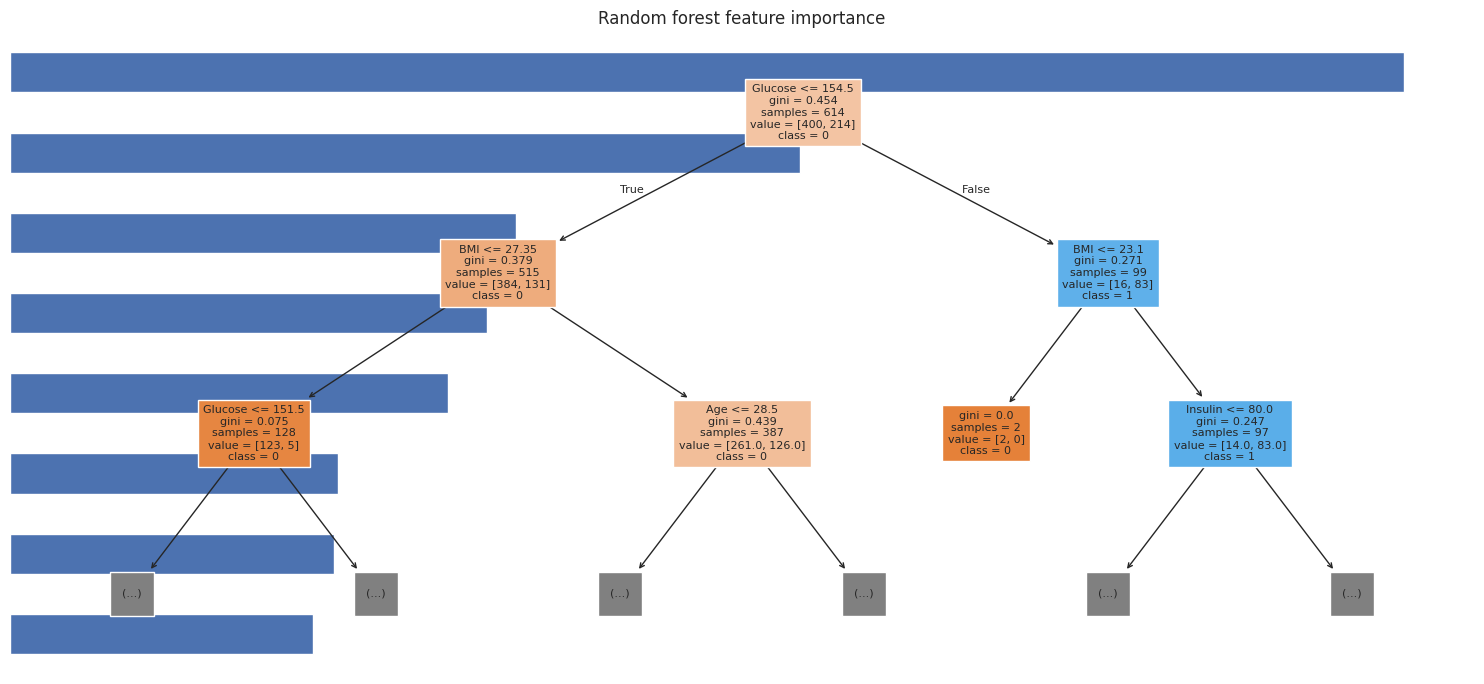

In [7]:
from sklearn.tree import plot_tree
plt.figure(figsize=(15, 7))
plot_tree(models['DecisionTree'], feature_names=feature_names,
          class_names=['0','1'], filled=True, max_depth=2, fontsize=8)
plt.title('Decision tree - first 3 levels (display truncated)')
save_fig('02_cay_quyet_dinh.png')
importance = pd.Series(models['RandomForest'].feature_importances_,
                       index=feature_names).sort_values(ascending=False)
importance.to_csv(OUT / 'feature_importance.csv')
importance.head(12).sort_values().plot.barh(title='Random forest feature importance')
save_fig('03_feature_importance.png')

## Nhận xét và giới hạn
Thông số mô hình được đặt trước để minh họa, chưa phải kết quả tối ưu siêu tham số. Imputer/encoder chỉ fit trên train. Cây hiển thị chỉ ba mức đầu; mô hình đã học có thể sâu hơn. Feature importance không biểu thị quan hệ nhân quả. So sánh hai mô hình trên cùng tập test, không kết luận ưu thế phổ quát từ một phép chia. Dùng bộ Pima 768 dòng; không thay bằng diabetes_prediction_dataset.csv 100000 dòng.